# code_120 · Graph size, sampled neighbors and explanation checks

**Book:** section 23.6. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_23_GUIDE.md), [run evidence](../CHAPTER_23_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_120).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2520;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2520


<a id="graph-scaling-contract"></a>
 ## Fixed fanout can miss a consequential connection
 Generate eighty connected building graphs. Forty train and ten select checkpoints at 8–12 nodes; ten final graphs share that size, while twenty final graphs have 24–40 nodes. Each graph has a hub connected to every other member plus a leaf ring. One observed hub connection has weight twenty and an admitted load near ±2; ordinary weights are one. The response is 0.4 own load + 0.6 weighted neighbor mean plus small noise. Fit actual one-layer graph models with mean or sum aggregation, two rates × 300 updates and own development checkpoints. A non-neural Ridge model on own/mean features is retained. Assess full graphs, then feed the frozen mean network uniformly sampled hub messages at fanouts 1/2/4. Known full weighted degree and degree/fanout correct the aggregate estimate; this does not make nonlinear predictions unbiased. Every sampled hub query remains in assessment.


,cohort,model,final_all_node_MSE,final_hub_MSE,graph_count
0,Source size,Relational Ridge,0.000315,0.000245,10
1,Source size,Mean graph,0.000406,0.000523,10
2,Source size,Sum graph,0.024632,0.006504,10
3,Larger graphs,Relational Ridge,0.000391,0.000804,20
4,Larger graphs,Mean graph,0.000452,0.001145,20
5,Larger graphs,Sum graph,0.021339,0.214794,20


,cohort,fanout,hub_query_repeats,sampled_hub_MSE,loss_SD_across_queries_and_samples,critical_edge_miss_fraction,analytic_critical_miss_fraction,finite_sample_aggregate_mean_error
0,Source size,1,1000,2.991508,8.388117,0.8900,0.879838,-0.090874
1,Source size,2,1000,1.538728,2.067363,0.7690,0.759675,-0.076548
2,Source size,4,1000,0.659295,0.334870,0.5320,0.519351,0.041716
3,Larger graphs,1,2000,5.043918,31.344172,0.9670,0.968051,0.153119
4,Larger graphs,2,2000,2.091489,9.200416,0.9405,0.936102,0.029818
5,Larger graphs,4,2000,1.005175,2.623194,0.8785,0.872204,-0.025693


,rule,Brier,accuracy
0,Own sign,0.000000,1.0
1,Neighbor smoothing,1.000000,0.0
2,Signed contrast,0.014209,1.0


{'original_hub_prediction': 0.4073787182110083, 'top_gradient_edge_other_member': 1, 'mean_top_two_Jaccard_under_input_noise': 1.0, 'top_gradient_removal_change': 0.46169037477553154, 'mean_uniform_incident_removal_change': 0.020990853623811406, 'largest_removal_effects': [{'edge_index': 0, 'other_member': 1, 'gradient_times_weight_magnitude': 0.4206838372027928, 'actual_removal_prediction_change': 0.46169037477553154}, {'edge_index': 33, 'other_member': 34, 'gradient_times_weight_magnitude': 0.017363762382504866, 'actual_removal_prediction_change': 0.012047729666387563}, {'edge_index': 18, 'other_member': 19, 'gradient_times_weight_magnitude': 0.01669134465580662, 'actual_removal_prediction_change': 0.01158869662171469}, {'edge_index': 29, 'other_member': 30, 'gradient_times_weight_magnitude': 0.015946263739998627, 'actual_removal_prediction_change': 0.011080059285530242}, {'edge_index': 30, 'other_member': 31, 'gradient_times_weight_magnitude': 0.01574330049769479, 'actual_removal_pr

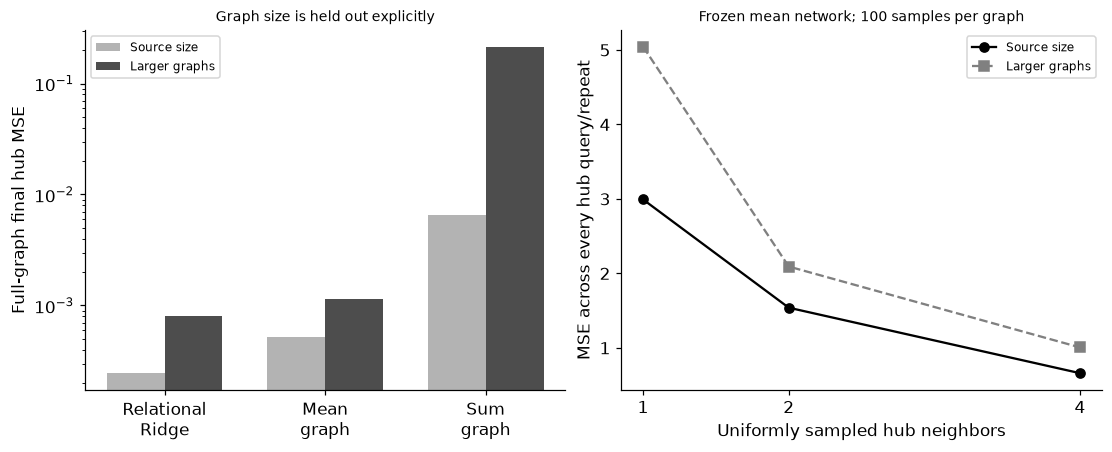

In [2]:
import copy
from sklearn.linear_model import Ridge
graphs=[];offset=0
for b in range(80):
    n=int(rng.integers(8,13) if b<60 else rng.integers(24,41));load=rng.normal(0,.2,(n,1));load[0]=rng.normal(0,.5);load[1]=rng.choice([-2.,2.])+rng.normal(0,.05);pairs={(0,j) for j in range(1,n)}
    pairs|={(min(i,1+i%(n-1)),max(i,1+i%(n-1))) for i in range(1,n)};pairs=np.array(sorted(pairs),dtype=int);weight=np.ones(len(pairs));weight[(pairs[:,0]==0)&(pairs[:,1]==1)]=20;a=np.zeros((n,n));a[pairs[:,0],pairs[:,1]]=weight;a+=a.T;mean=a@load/a.sum(1)[:,None];response=.4*load+.6*mean+rng.normal(0,.02,(n,1));graphs.append(dict(n=n,load=load,pairs=pairs,weight=weight,mean=mean,response=response,offset=offset));offset+=n
x=torch.tensor(np.concatenate([g['load'] for g in graphs]));y=torch.tensor(np.concatenate([g['response'] for g in graphs])).ravel();owner=np.concatenate([np.full(g['n'],b) for b,g in enumerate(graphs)]);u=torch.tensor(np.concatenate([g['pairs'][:,0]+g['offset'] for g in graphs]));v=torch.tensor(np.concatenate([g['pairs'][:,1]+g['offset'] for g in graphs]));weights=torch.tensor(np.concatenate([g['weight'] for g in graphs]));assert np.all(owner[u.numpy()]==owner[v.numpy()])
def aggregate(values,left,right,edge_weight,kind='Mean'):
    source=torch.cat([left,right]);destination=torch.cat([right,left]);doubled=torch.cat([edge_weight,edge_weight]);total=torch.zeros_like(values);total.index_add_(0,destination,values[source]*doubled[:,None])
    if kind=='Sum':return total
    degree=torch.zeros(len(values),dtype=values.dtype);degree.index_add_(0,destination,doubled);assert torch.all(degree>0);return total/degree[:,None]
mean=aggregate(x,u,v,weights);np.testing.assert_allclose(mean.numpy(),np.concatenate([g['mean'] for g in graphs]),atol=1e-12);own_mean=torch.cat([x,mean],dim=1).numpy();train=owner<40;dev=(owner>=40)&(owner<50);ridge=Ridge(alpha=1e-6).fit(own_mean[train],y.numpy()[train]);predictions={'Relational Ridge':ridge.predict(own_mean)};fitted={};candidates=[]
class GraphResponse(nn.Module):
    def __init__(self,kind,center,scale):super().__init__();self.kind=kind;self.register_buffer('center',center);self.register_buffer('scale',scale);self.net=nn.Sequential(nn.Linear(2,8),nn.ReLU(),nn.Linear(8,1))
    def from_aggregate(self,own,neighbors):return self.net((torch.cat([own,neighbors],dim=1)-self.center)/self.scale).ravel()
    def forward(self,values,left,right,edge_weight):return self.from_aggregate(values,aggregate(values,left,right,edge_weight,self.kind))
for kind in ['Mean','Sum']:
    features=torch.cat([x,aggregate(x,u,v,weights,kind)],dim=1);center=features[train].mean(0);scale=features[train].std(0,unbiased=False);family_best=np.inf
    for rate in [.005,.01]:
        torch.manual_seed(SEED);model=GraphResponse(kind,center,scale);optimizer=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.001);best=np.inf
        for step in range(1,301):
            optimizer.zero_grad();pred=model(x,u,v,weights);loss=torch.mean((pred[train]-y[train])**2);loss.backward();optimizer.step()
            if step%10==0:
                with torch.no_grad():score=float(torch.mean((model(x,u,v,weights)[dev]-y[dev])**2))
                if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step
        candidates.append({'aggregation':kind,'rate':rate,'development_MSE':best,'best_step':best_step})
        if best<family_best:family_best=best;chosen=(rate,best_step,state)
    rate,best_step,state=chosen;model.load_state_dict(state);model.eval();fitted[kind]=model
    with torch.no_grad():predictions[kind+' graph']=model(x,u,v,weights).numpy()
rows=[];hubs=np.array([g['offset'] for g in graphs])
for cohort,building_ids in [('Source size',range(50,60)),('Larger graphs',range(60,80))]:
    mask=np.isin(owner,list(building_ids));hub=hubs[list(building_ids)]
    for name,pred in predictions.items():rows.append({'cohort':cohort,'model':name,'final_all_node_MSE':float(np.mean((pred[mask]-y.numpy()[mask])**2)),'final_hub_MSE':float(np.mean((pred[hub]-y.numpy()[hub])**2)),'graph_count':len(building_ids)})
# A disconnected union reproduces separately evaluated graphs with the same frozen parameters.
g=graphs[60];start=g['offset'];local_x=x[start:start+g['n']];local_u=torch.tensor(g['pairs'][:,0]);local_v=torch.tensor(g['pairs'][:,1]);local_w=torch.tensor(g['weight'])
with torch.no_grad():separate=fitted['Mean'](local_x,local_u,local_v,local_w);joined=fitted['Mean'](x,u,v,weights)[start:start+g['n']];torch.testing.assert_close(separate,joined,atol=1e-12,rtol=1e-12)
sampling=[]
for cohort,building_ids in [('Source size',range(50,60)),('Larger graphs',range(60,80))]:
    for fanout in [1,2,4]:
        losses=[];misses=[];biases=[];expected=[]
        for b in building_ids:
            graph=graphs[b];n=graph['n'];degree=n-1;neighbors=np.arange(1,n);connection=np.ones(degree);connection[0]=20;denominator=connection.sum();payload=graph['load'][1:,0];full=float(connection@payload/denominator);np.testing.assert_allclose(np.mean(degree*connection*payload/denominator),full,atol=1e-12);expected.append(1-fanout/degree)
            for repeat in range(100):
                chosen=rng.choice(degree,size=fanout,replace=False);estimate=float(degree/fanout*np.sum(connection[chosen]*payload[chosen])/denominator)
                with torch.no_grad():pred=float(fitted['Mean'].from_aggregate(torch.tensor(graph['load'][:1]),torch.tensor([[estimate]]))[0])
                losses.append((pred-float(graph['response'][0,0]))**2);misses.append(0 not in chosen);biases.append(estimate-full)
        sampling.append({'cohort':cohort,'fanout':fanout,'hub_query_repeats':len(losses),'sampled_hub_MSE':float(np.mean(losses)),'loss_SD_across_queries_and_samples':float(np.std(losses,ddof=1)),'critical_edge_miss_fraction':float(np.mean(misses)),'analytic_critical_miss_fraction':float(np.mean(expected)),'finite_sample_aggregate_mean_error':float(np.mean(biases))})
# Heterophily fixture: the informative own sign is opposite every neighbor sign.
fixture=np.array([-1.,1.,-1.,1.]);cycle=np.array([[0,1,0,1],[1,0,1,0],[0,1,0,1],[1,0,1,0]])/2;label=(fixture>0).astype(float);neighbor=cycle@fixture;own_probability=(fixture+1)/2;neighbor_probability=(neighbor+1)/2;signed_probability=1/(1+np.exp(-(fixture-neighbor)));heterophily=[{'rule':name,'Brier':float(np.mean((prob-label)**2)),'accuracy':float(np.mean((prob>=.5)==label))} for name,prob in [('Own sign',own_probability),('Neighbor smoothing',neighbor_probability),('Signed contrast',signed_probability)]];assert heterophily[1]['accuracy']==0 and heterophily[2]['accuracy']==1
# Normalized edge-weight gradients and actual removal effects on one frozen hub computation.
def attribution(values):
    w=local_w.clone().requires_grad_(True);pred=fitted['Mean'](values,local_u,local_v,w)[0];gradient=torch.autograd.grad(pred,w)[0];return float(pred.detach()),(torch.abs(gradient)*local_w).detach().numpy()
original,importance=attribution(local_x);incident=np.flatnonzero((local_u.numpy()==0)|(local_v.numpy()==0));rank=incident[np.argsort(-importance[incident],kind='stable')];top=set(rank[:2]);jaccard=[]
for repeat in range(20):
    _,changed_importance=attribution(local_x+torch.tensor(rng.normal(0,.02,local_x.shape)));changed=set(incident[np.argsort(-changed_importance[incident],kind='stable')][:2]);jaccard.append(len(top&changed)/len(top|changed))
effects=[]
for edge in incident:
    changed=local_w.clone();changed[edge]=0
    with torch.no_grad():after=float(fitted['Mean'](local_x,local_u,local_v,changed)[0])
    effects.append({'edge_index':int(edge),'other_member':int(local_v[edge] if local_u[edge]==0 else local_u[edge]),'gradient_times_weight_magnitude':float(importance[edge]),'actual_removal_prediction_change':abs(after-original)})
largest=sorted(effects,key=lambda r:-r['actual_removal_prediction_change']);explanation={'original_hub_prediction':original,'top_gradient_edge_other_member':next(r['other_member'] for r in effects if r['edge_index']==rank[0]),'mean_top_two_Jaccard_under_input_noise':float(np.mean(jaccard)),'top_gradient_removal_change':next(r['actual_removal_prediction_change'] for r in effects if r['edge_index']==rank[0]),'mean_uniform_incident_removal_change':float(np.mean([r['actual_removal_prediction_change'] for r in effects])),'largest_removal_effects':largest[:6],'input_noise_SD':.02,'perturbation_repeats':20}
RESULTS.update(size_assessment=rows,candidates=candidates,source_train_graphs=40,source_development_graphs=10,source_final_graphs=10,larger_final_graphs=20,source_node_range=[8,12],larger_node_range=[24,40],sampling=sampling,heterophily_fixture=heterophily,explanation_fixture=explanation,disconnected_batch_max_error=float(torch.max(torch.abs(separate-joined))),training_only_aggregate_scaling=True);display(pd.DataFrame(rows));display(pd.DataFrame(sampling));display(pd.DataFrame(heterophily));print(explanation)
fig,axes=plt.subplots(1,2,figsize=(10,4));names=list(predictions);xx=np.arange(3)
for offset,cohort,color in [(-.18,'Source size','.7'),(.18,'Larger graphs','.3')]:
    values=[next(r['final_hub_MSE'] for r in rows if r['cohort']==cohort and r['model']==name) for name in names];axes[0].bar(xx+offset,values,width=.36,color=color,label=cohort)
axes[0].set(yscale='log',xticks=xx,xticklabels=['Relational\nRidge','Mean\ngraph','Sum\ngraph'],ylabel='Full-graph final hub MSE',title='Graph size is held out explicitly');axes[0].legend(fontsize=8)
for cohort,style,color in [('Source size','o-','black'),('Larger graphs','s--','.5')]:
    subset=[r for r in sampling if r['cohort']==cohort];axes[1].plot([r['fanout'] for r in subset],[r['sampled_hub_MSE'] for r in subset],style,color=color,label=cohort)
axes[1].set(xticks=[1,2,4],xlabel='Uniformly sampled hub neighbors',ylabel='MSE across every hub query/repeat',title='Frozen mean network; 100 samples per graph');axes[1].legend(fontsize=8);plt.show()


<a id="graph-failure-limits"></a>
 ## Graph dependence affects sampling and explanations
 The larger cohort changes node count and hub degree, not the response formula. Mean and sum models use separately training-fitted aggregate scaling. Sampling is uniform without replacement; the degree/fanout correction and known full weighted-degree denominator make the linear aggregate conditionally unbiased. Finite repeated estimates still fluctuate, and nonlinear predictions need not preserve that expectation. Critical-edge miss probability is one minus fanout/degree, so the same fixed fanout sees less of a larger hub. The separate alternating-sign graph shows that neighborhood smoothing can destroy a valid own-node signal under heterophily. Explanation audits retain both normalized edge-weight gradient magnitudes and actual connection-removal changes; recomputing normalization matters. Top-two overlap under admitted input noise checks stability, while removal effects check the frozen computation's sensitivity. Neither establishes a causal effect of physically removing a connection or validates an engineering intervention.


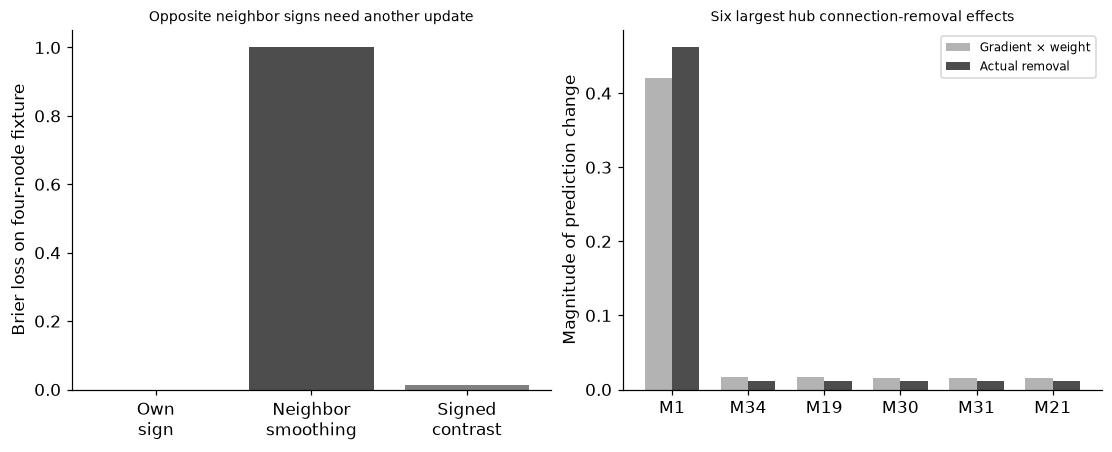

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(3),[r['Brier'] for r in heterophily],color=['.7','.3','.5']);axes[0].set(xticks=range(3),xticklabels=['Own\nsign','Neighbor\nsmoothing','Signed\ncontrast'],ylabel='Brier loss on four-node fixture',title='Opposite neighbor signs need another update')
selected=largest[:6];xx=np.arange(len(selected));axes[1].bar(xx-.18,[r['gradient_times_weight_magnitude'] for r in selected],width=.36,color='.7',label='Gradient × weight');axes[1].bar(xx+.18,[r['actual_removal_prediction_change'] for r in selected],width=.36,color='.3',label='Actual removal');axes[1].set(xticks=xx,xticklabels=[f"M{r['other_member']}" for r in selected],ylabel='Magnitude of prediction change',title='Six largest hub connection-removal effects');axes[1].legend(fontsize=8);plt.show()
assert all(np.isfinite(r['sampled_hub_MSE']) for r in sampling)


In [4]:
summary={'example_id':'code_120','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual graph-size holdout', 'mean versus sum aggregation transfer', 'uniform neighbor sampling with known degree correction', 'heterophily counterexample', 'edge-attribution fidelity and stability'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual graph-size holdout", "mean versus sum aggregation transfer", "uniform neighbor sampling with known degree correction", "heterophily counterexample", "edge-attribution fidelity and stability"], "elapsed_seconds": 1.692, "example_id": "code_120", "hardware": "Darwin arm64 CPU", "results": {"candidates": [{"aggregation": "Mean", "best_step": 300, "development_MSE": 0.0012762798599804171, "rate": 0.005}, {"aggregation": "Mean", "best_step": 300, "development_MSE": 0.0005525438181066194, "rate": 0.01}, {"aggregation": "Sum", "best_step": 300, "development_MSE": 0.022785491637766952, "rate": 0.005}, {"aggregation": "Sum", "best_step": 300, "development_MSE": 0.021393945835010825, "rate": 0.01}], "disconnected_batch_max_error": 1.1102230246251565e-16, "explanation_fixture": {"input_noise_SD": 0.02, "largest_removal_effects": [{"actual_removal_prediction_change": 0.46169037477553154, "edge_index": 0, "gradient_times_weight_magnitude": 0